In [ ]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.preprocessing import image

ROOT_DIR = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
train_dir = ROOT_DIR / 'data' / 'horses-vs-humans' / 'train'
val_dir = ROOT_DIR / 'data' / 'horses-vs-humans' / 'validation'

train_datagen = ImageDataGenerator(rescale=1/255.0)
val_datagen = ImageDataGenerator(rescale=1/255.0)

train_generator = train_datagen.flow_from_directory(
    str(train_dir),
    target_size=(150, 150),
    batch_size=128,
    class_mode='binary'
)

validation_generator = val_datagen.flow_from_directory(
    str(val_dir),
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary'
)

Found 1027 images belonging to 2 classes.
Found 256 images belonging to 2 classes.


In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(150, 150, 3)),

    tf.keras.layers.Conv2D(16, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    loss='binary_crossentropy',
    optimizer=RMSprop(learning_rate=0.001),
    metrics=['accuracy']
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 148, 148, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 74, 74, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 72, 72, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 34, 34, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 18496)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │     9,470,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,494,561 (36.22 MB)

 Trainable params: 9,494,561 (36.22 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
import time
t0 = time.time()
history = model.fit(
    train_generator,
    steps_per_epoch=8,
    epochs=15,
    validation_data=validation_generator,
    validation_steps=8,
    verbose=1
)
duration = time.time() - t0
print(f'Час навчання моделі (150x150, 15 епох): {duration:.2f} с ({duration/15:.2f} с/епоха)')

Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 433ms/step - accuracy: 0.5217 - loss: 0.8954 - val_accuracy: 0.5000 - val_loss: 0.6595
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.5781 - loss: 0.6588 - val_accuracy: 0.5117 - val_loss: 0.6370
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 438ms/step - accuracy: 0.7041 - loss: 0.6706 - val_accuracy: 0.5312 - val_loss: 0.9971
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.6641 - loss: 0.4755 - val_accuracy: 0.8477 - val_loss: 0.4098
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 494ms/step - accuracy: 0.7976 - loss: 0.5361 - val_accuracy: 0.6484 - val_loss: 0.6664
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - accuracy: 0.9141 - loss: 0.4145 - val_accuracy: 0.7148 - val_loss: 0.6879
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 497ms/step - accuracy: 0.8643 - loss: 0.4494 - val_accuracy: 0.8359 - val_loss: 0.4910
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.9297 - loss: 0.2831 - val_accuracy: 0.8203 - val_loss: 0.6

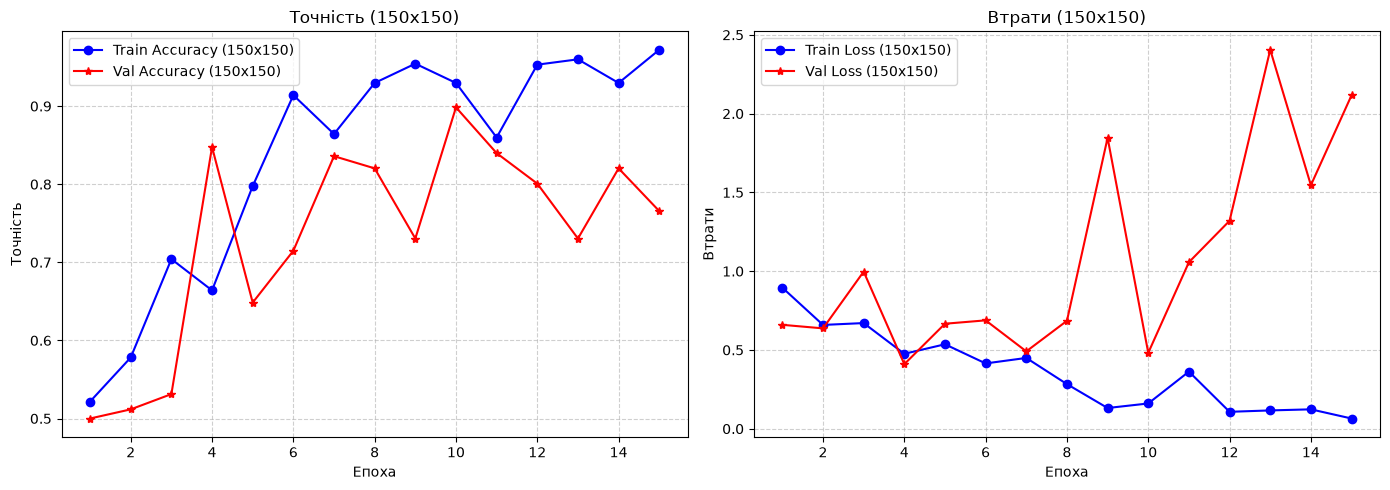

In [10]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'bo-', label='Train Accuracy (150x150)')
plt.plot(epochs_range, val_acc, 'r*-', label='Val Accuracy (150x150)')
plt.title('Точність (150x150)')
plt.xlabel('Епоха')
plt.ylabel('Точність')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'bo-', label='Train Loss (150x150)')
plt.plot(epochs_range, val_loss, 'r*-', label='Val Loss (150x150)')
plt.title('Втрати (150x150)')
plt.xlabel('Епоха')
plt.ylabel('Втрати')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

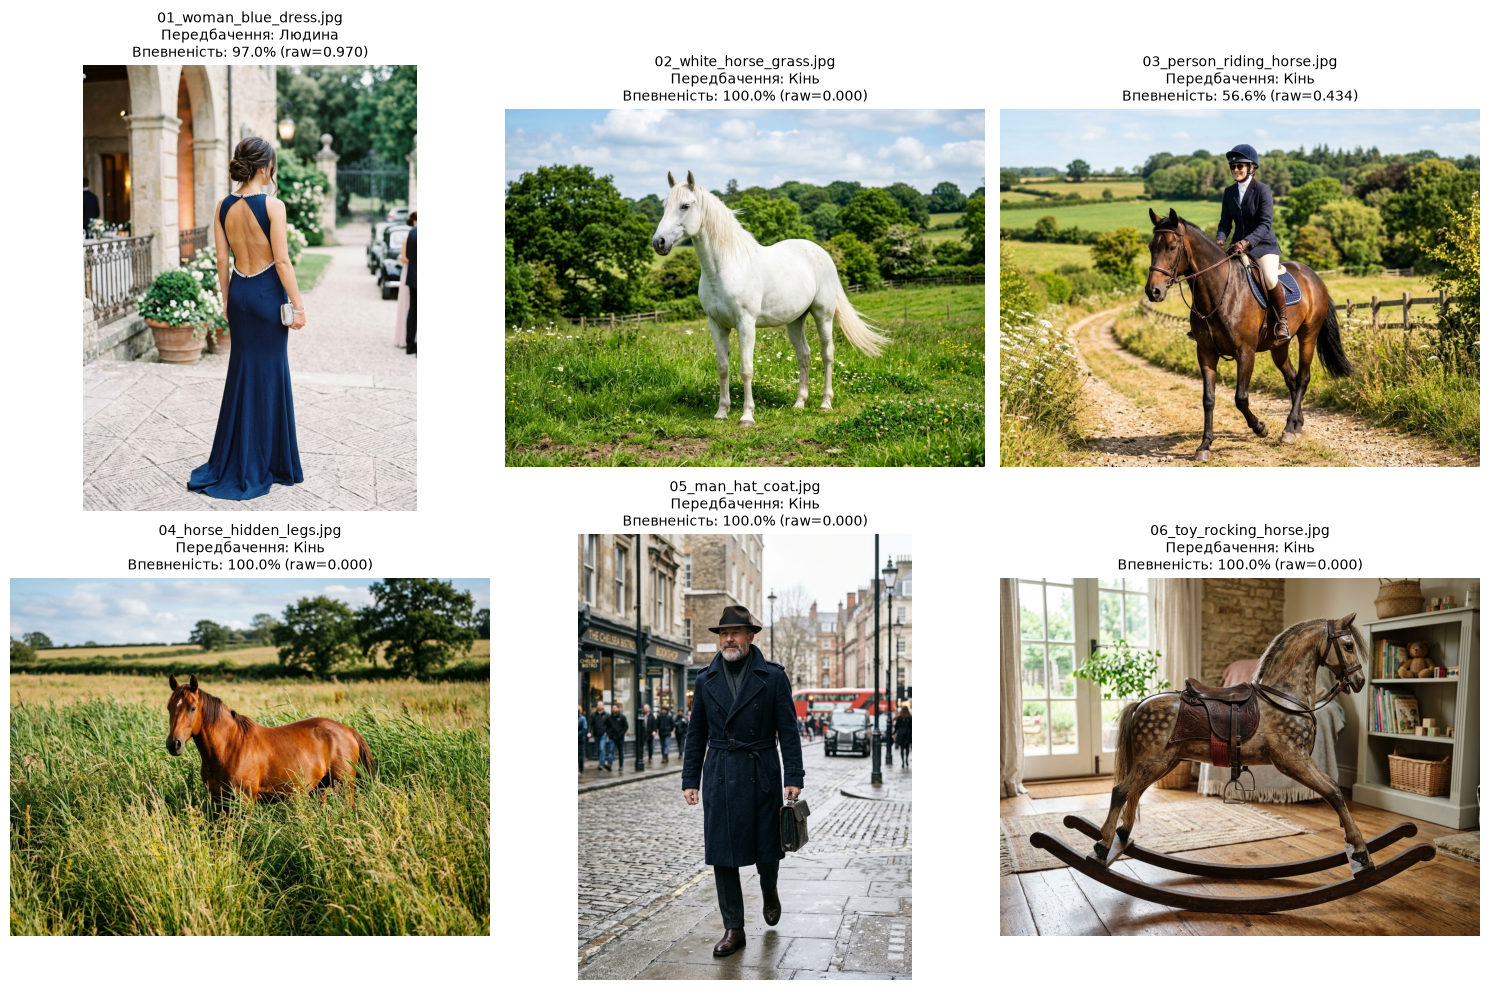

In [11]:
from pathlib import Path

test_images_dir = ROOT_DIR / 'test_images' / 'horses_humans'
test_files = sorted(list(test_images_dir.glob('*.jpg')))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, img_path in enumerate(test_files):
    img = image.load_img(img_path, target_size=(150, 150))
    x = image.img_to_array(img) / 255.0
    x = np.expand_dims(x, axis=0)
    prob = float(model.predict(x, verbose=0)[0][0])
    pred_class = 'Людина' if prob > 0.5 else 'Кінь'
    confidence = prob if prob > 0.5 else (1.0 - prob)
    
    display_img = Image.open(img_path)
    axes[idx].imshow(display_img)
    axes[idx].set_title(f'{img_path.name}\nПередбачення: {pred_class}\nВпевненість: {confidence*100:.1f}% (raw={prob:.3f})',
                        fontsize=10)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()